In [1]:
#1. Load the cleaned dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

df = pd.read_csv("../data/student_performance_cleaned.csv")

df.head()

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance_category,pass
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Fail,Fail
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Fail,Fail
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Average,Pass
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Good,Pass
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Average,Pass


In [2]:
#2 Basic Overview
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Dataset Shape: (395, 35)

Columns:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3', 'performance_category', 'pass']


Analysis 1 — Overall Performance

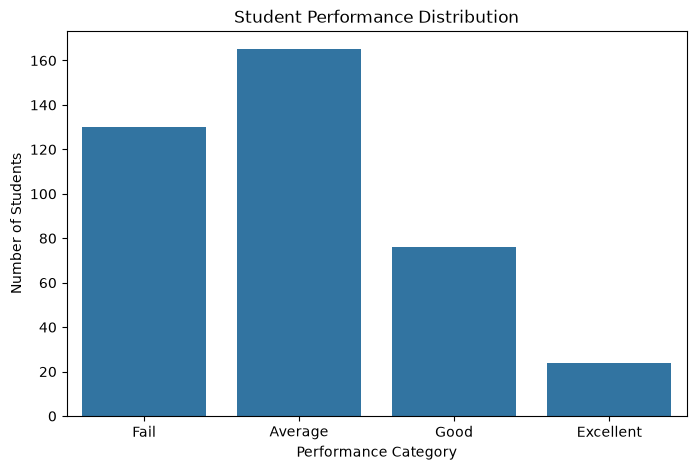

In [3]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="performance_category",
    order=["Fail", "Average", "Good", "Excellent"]
)

plt.title("Student Performance Distribution")
plt.xlabel("Performance Category")
plt.ylabel("Number of Students")
plt.show()

In [4]:
performance_pct = (
    df["performance_category"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

performance_pct

performance_category
Average      41.77
Fail         32.91
Good         19.24
Excellent     6.08
Name: proportion, dtype: float64

Analysis 2 — Study Time vs Performance

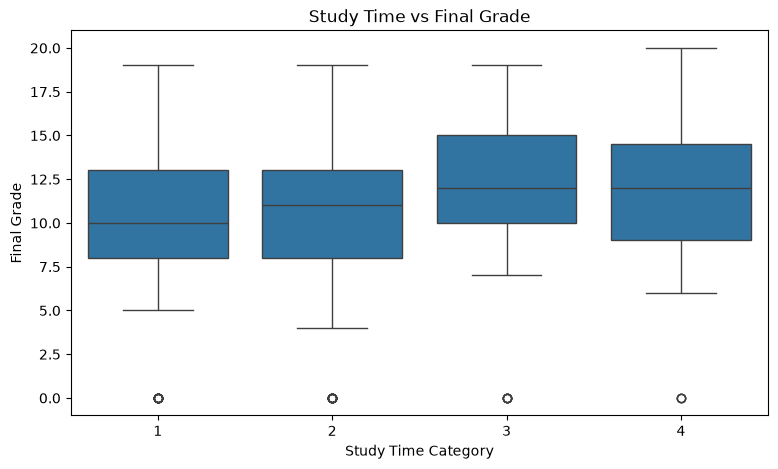

In [5]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="studytime",
    y="G3"
)

plt.title("Study Time vs Final Grade")
plt.xlabel("Study Time Category")
plt.ylabel("Final Grade")
plt.show()

In [6]:
df.groupby("studytime")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
studytime,,,
1,105,10.05,10.0
2,198,10.17,11.0
3,65,11.40,12.0
4,27,11.26,12.0


Analysis 3 — Absences vs Performance

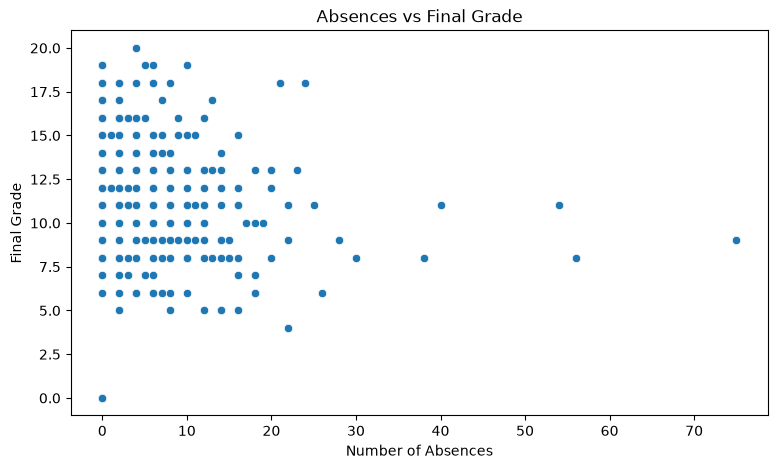

In [7]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x="absences",
    y="G3"
)

plt.title("Absences vs Final Grade")
plt.xlabel("Number of Absences")
plt.ylabel("Final Grade")
plt.show()

In [8]:
df["absences"].corr(df["G3"])

np.float64(0.03424731615006931)

Analysis 4 — Previous Failures

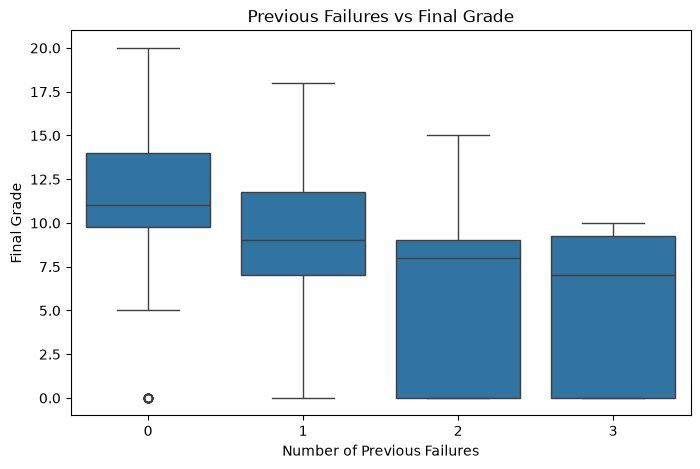

In [9]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="failures",
    y="G3"
)

plt.title("Previous Failures vs Final Grade")
plt.xlabel("Number of Previous Failures")
plt.ylabel("Final Grade")
plt.show()

Analysis 5 — Mother's Education

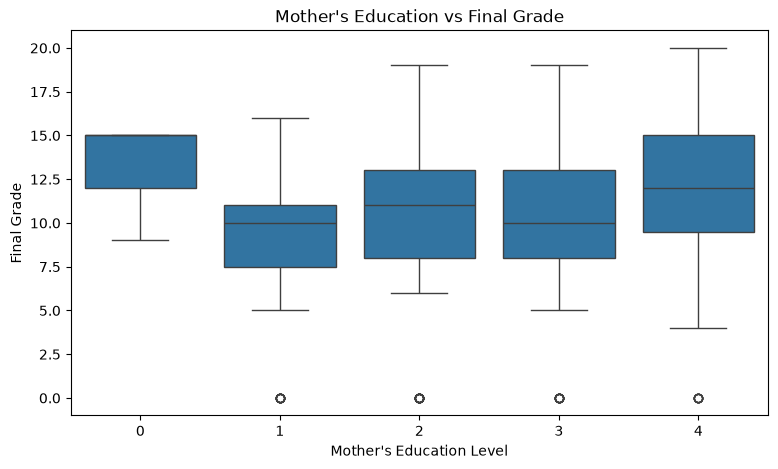

In [10]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Medu",
    y="G3"
)

plt.title("Mother's Education vs Final Grade")
plt.xlabel("Mother's Education Level")
plt.ylabel("Final Grade")
plt.show()

In [11]:
df.groupby("Medu")["G3"].mean().round(2)

Medu
0    13.00
1     8.68
2     9.73
3    10.30
4    11.76
Name: G3, dtype: float64

Analysis 6 — Father's Education

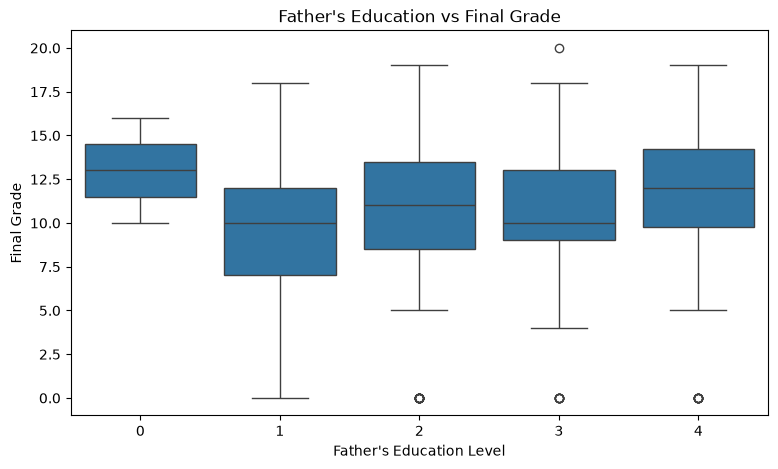

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Fedu",
    y="G3"
)

plt.title("Father's Education vs Final Grade")
plt.xlabel("Father's Education Level")
plt.ylabel("Final Grade")
plt.show()

Analysis 7 — Internet Access

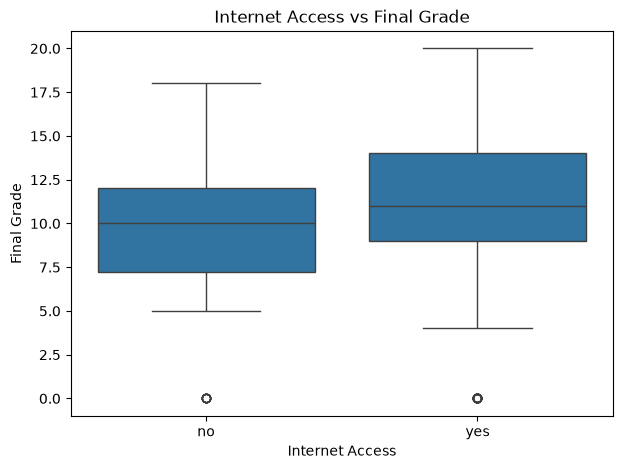

In [14]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="internet",
    y="G3"
)

plt.title("Internet Access vs Final Grade")
plt.xlabel("Internet Access")
plt.ylabel("Final Grade")
plt.show()

In [15]:
df.groupby("internet")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
internet,,,
no,66,9.41,10.0
yes,329,10.62,11.0


Analysis 8 — Gender vs Performance

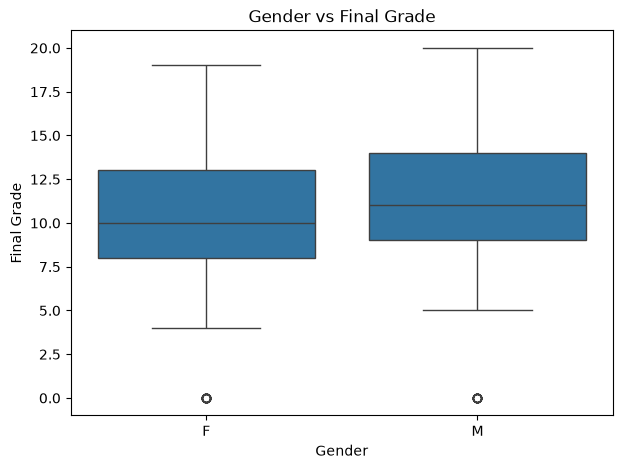

In [16]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="sex",
    y="G3"
)

plt.title("Gender vs Final Grade")
plt.xlabel("Gender")
plt.ylabel("Final Grade")
plt.show()

In [17]:
df.groupby("sex")["G3"].agg(
    ["count", "mean", "median"]
).round(2)

,count,mean,median
sex,,,
F,208,9.97,10.0
M,187,10.91,11.0


Analysis 9 — School Performance

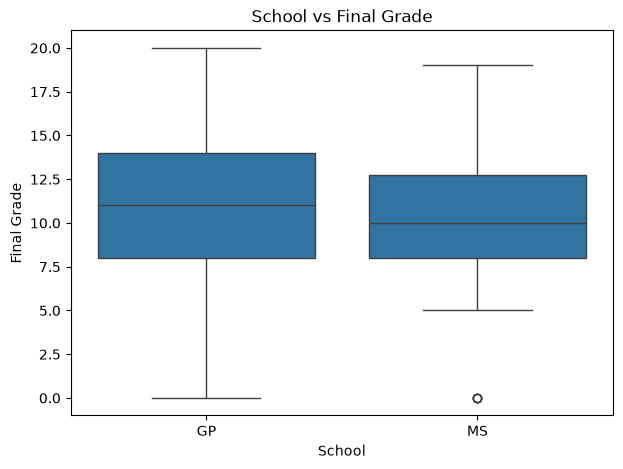

In [22]:
plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x="school",
    y="G3"
)

plt.title("School vs Final Grade")
plt.xlabel("School")
plt.ylabel("Final Grade")
plt.show()

Analysis 10 — Correlation Heatmap

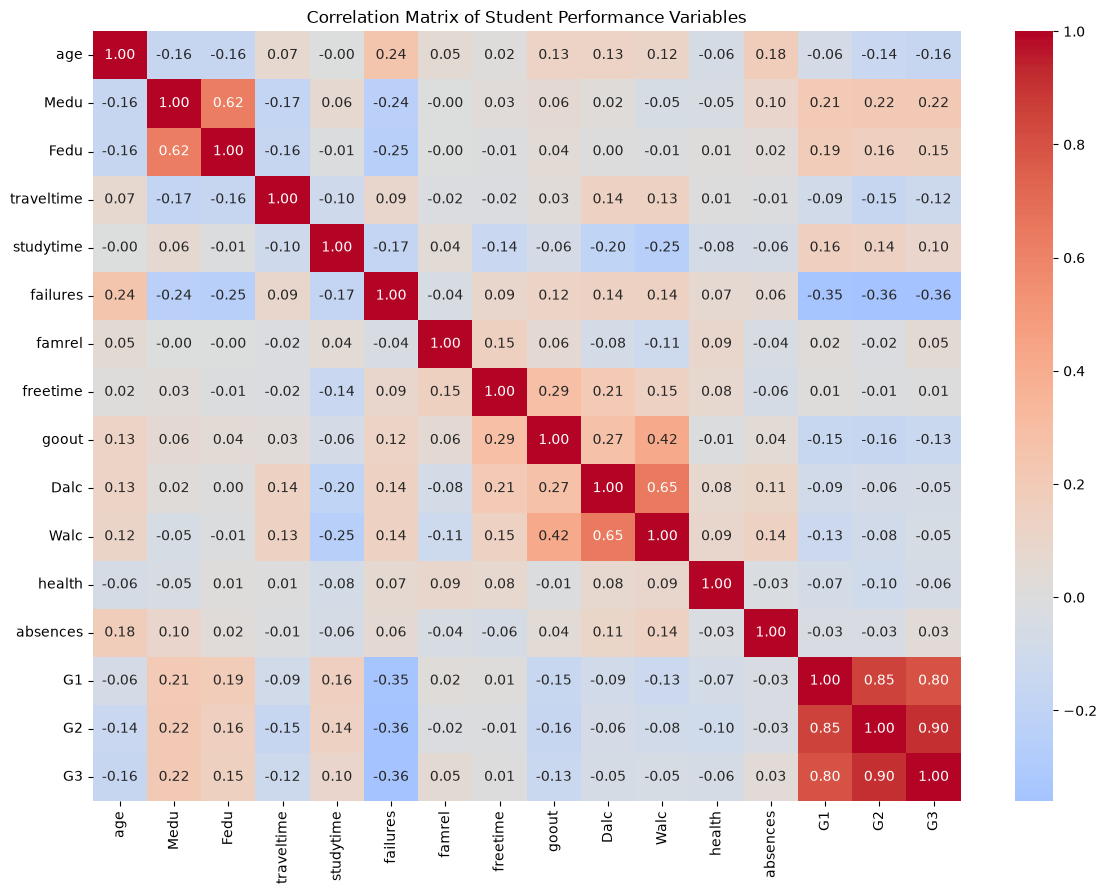

In [21]:
numeric_df = df.select_dtypes(
    include=["int64", "float64"]
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Matrix of Student Performance Variables")
plt.show()

Analysis 11 — G1, G2 and G3

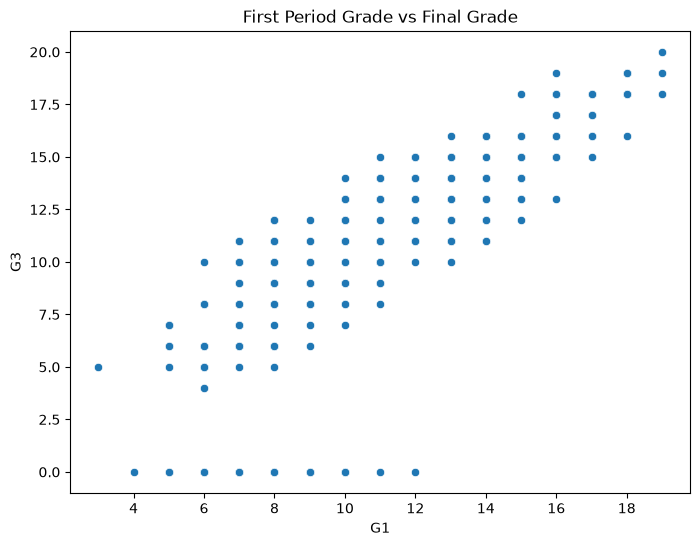

In [23]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="G1",
    y="G3"
)

plt.title("First Period Grade vs Final Grade")
plt.show()

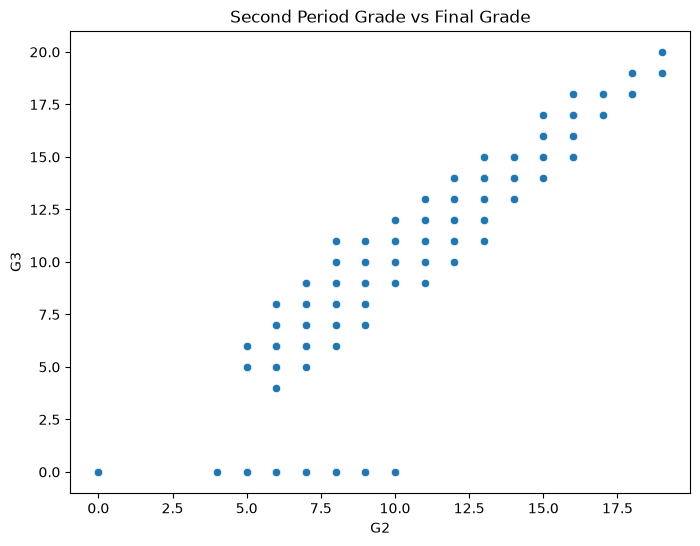

In [24]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="G2",
    y="G3"
)

plt.title("Second Period Grade vs Final Grade")
plt.show()

In [25]:
df[["G1", "G2", "G3"]].corr()

,G1,G2,G3
G1,1.000000,0.852118,0.801468
G2,0.852118,1.000000,0.904868
G3,0.801468,0.904868,1.000000
